# What Drives the Price of a Home? Separating the House from the Neighborhood
### Capstone Final Report
**Author:** Neda Nadjmabadi

This notebook answers a practical question for home sellers: of everything that sets a home's sale price,
how much comes from the **house itself** (its size, quality, and condition) and how much comes from the
**location** around it (how close it is to the city, and which neighborhood it sits in)? Knowing the split
tells an owner where a renovation budget is worth spending and where it is not.

The work follows the **CRISP-DM** process: business understanding, data understanding, data preparation,
modeling, and evaluation. I build five models, compare them fairly, and translate the result into plain
recommendations a non-technical reader can act on.

## 1. Business Understanding

**Research question.** Which features of a home, and which qualities of its location, have the biggest effect
on its sale price, and how accurately can we predict what a house will sell for once we account for both?

**Who this is for.** The person this helps most is someone preparing to sell an older home. They face a list
of spending decisions with no clear way to rank them: redo the kitchen or just refresh it, finish the
basement or leave it, replace the garage door or not. Most sellers decide on instinct, or on the advice of a
contractor who is paid to recommend more work. This analysis replaces guesswork with evidence by separating
the price that comes from the house, which an owner can change, from the price that comes from the
neighborhood, which they cannot.

In [1]:
# ---- Libraries ----
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

sns.set_theme(style='whitegrid', palette='muted')
pd.set_option('display.float_format', lambda x: f'{x:,.2f}')
RANDOM_STATE = 42

## 2. Data Understanding

The data is about 21,000 home sales from King County, Washington (which includes Seattle), covering May 2014
to May 2015. Each row is one sale and records the home's physical attributes, its location (ZIP code,
latitude, longitude), and the final sale price, which is what the models predict.

In [2]:
df = pd.read_csv('../data/kc_house_data.csv')
print('Rows, columns:', df.shape)
df.head()

Rows, columns: (21613, 21)


,id,date,price,bedrooms,bathrooms,sqft_living,sqft_lot,floors,waterfront,view,...,grade,sqft_above,sqft_basement,yr_built,yr_renovated,zipcode,lat,long,sqft_living15,sqft_lot15
0,7129300520,20141013T000000,"221,900.00",3,1.00,1180,5650,1.00,0,0,...,7,1180,0,1955,0,98178,47.51,-122.26,1340,5650
1,6414100192,20141209T000000,"538,000.00",3,2.25,2570,7242,2.00,0,0,...,7,2170,400,1951,1991,98125,47.72,-122.32,1690,7639
2,5631500400,20150225T000000,"180,000.00",2,1.00,770,10000,1.00,0,0,...,6,770,0,1933,0,98028,47.74,-122.23,2720,8062
3,2487200875,20141209T000000,"604,000.00",4,3.00,1960,5000,1.00,0,0,...,7,1050,910,1965,0,98136,47.52,-122.39,1360,5000
4,1954400510,20150218T000000,"510,000.00",3,2.00,1680,8080,1.00,0,0,...,8,1680,0,1987,0,98074,47.62,-122.05,1800,7503


In [3]:
# Structure and completeness
df.info()
print('\nTotal missing values:', int(df.isna().sum().sum()))
print('Duplicate home ids:', int(df['id'].duplicated().sum()))

<class 'pandas.DataFrame'>
RangeIndex: 21613 entries, 0 to 21612
Data columns (total 21 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   id             21613 non-null  int64  
 1   date           21613 non-null  str    
 2   price          21613 non-null  float64
 3   bedrooms       21613 non-null  int64  
 4   bathrooms      21613 non-null  float64
 5   sqft_living    21613 non-null  int64  
 6   sqft_lot       21613 non-null  int64  
 7   floors         21613 non-null  float64
 8   waterfront     21613 non-null  int64  
 9   view           21613 non-null  int64  
 10  condition      21613 non-null  int64  
 11  grade          21613 non-null  int64  
 12  sqft_above     21613 non-null  int64  
 13  sqft_basement  21613 non-null  int64  
 14  yr_built       21613 non-null  int64  
 15  yr_renovated   21613 non-null  int64  
 16  zipcode        21613 non-null  int64  
 17  lat            21613 non-null  float64
 18  long           21

In [4]:
# A first look at the target we are predicting
df['price'].describe()

count      21,613.00
mean      540,088.14
std       367,127.20
min        75,000.00
25%       321,950.00
50%       450,000.00
75%       645,000.00
max     7,700,000.00
Name: price, dtype: float64

## 3. Data Cleaning

The file has no missing values, but three things need attention: the sale date is stored as text, some homes
appear more than once (they sold twice in the window), and a few records are clearly data-entry errors, such
as a home listed with 33 bedrooms. I parse the date, keep only the most recent sale per home, and drop the
impossible rows.

In [5]:
# Parse the sale date from its text format
df['date'] = pd.to_datetime(df['date'], format='%Y%m%dT%H%M%S')

rows_before = len(df)

# A home that sold twice appears twice; keep its most recent sale
df = df.drop_duplicates(subset='id', keep='last')

# Drop impossible or extreme-error records
df = df[(df['bedrooms'] > 0) & (df['bedrooms'] <= 11)]
df = df[df['price'] > 0]

print(f'Removed {rows_before - len(df):,} rows. Clean dataset: {len(df):,} rows')

Removed 191 rows. Clean dataset: 21,422 rows


## 4. Feature Engineering

Some of what matters for price is not a raw column but has to be built:

- **`age_at_sale`** — how old the home was when it sold.
- **`was_renovated`** — whether the home had ever been renovated.
- **`has_basement`** — a simple flag from basement square footage.
- **`dist_seattle`** — straight-line distance in miles from each home to downtown Seattle, a clean stand-in
  for *proximity to the city*.

For the neighborhood itself I keep **`zipcode`** and later feed it to the models as a categorical variable, so
each of the 70 ZIP codes can carry its own price level. This captures local demand without me having to hand-build
a score, and it avoids leaking price information into the features.

In [6]:
# Straight-line (haversine) distance to downtown Seattle, in miles
SEATTLE_LAT, SEATTLE_LON = 47.6062, -122.3321

def haversine_miles(lat, lon, lat0=SEATTLE_LAT, lon0=SEATTLE_LON):
    R = 3958.8  # Earth radius in miles
    dlat, dlon = np.radians(lat - lat0), np.radians(lon - lon0)
    a = np.sin(dlat/2)**2 + np.cos(np.radians(lat0))*np.cos(np.radians(lat))*np.sin(dlon/2)**2
    return 2 * R * np.arcsin(np.sqrt(a))

df['age_at_sale']   = (df['date'].dt.year - df['yr_built']).clip(lower=0)
df['was_renovated'] = (df['yr_renovated'] > 0).astype(int)
df['has_basement']  = (df['sqft_basement'] > 0).astype(int)
df['dist_seattle']  = haversine_miles(df['lat'].values, df['long'].values)
df['price_per_sqft'] = df['price'] / df['sqft_living']   # for EDA only, not a model input

df[['age_at_sale','was_renovated','has_basement','dist_seattle']].describe()

,age_at_sale,was_renovated,has_basement,dist_seattle
count,"21,422.00","21,422.00","21,422.00","21,422.00"
mean,43.23,0.04,0.39,11.47
std,29.39,0.20,0.49,6.62
min,0.00,0.00,0.00,0.61
25%,17.00,0.00,0.00,6.07
50%,39.00,0.00,0.00,10.26
75%,63.00,0.00,1.00,15.70
max,115.00,1.00,1.00,47.90


## 5. Exploratory Data Analysis

### 5.1 The target is right-skewed
Prices run from tens of thousands to several million dollars, with a long tail of expensive homes. Taking the
logarithm makes the distribution roughly symmetric, which is why the models predict **log price** and then
convert back to dollars.

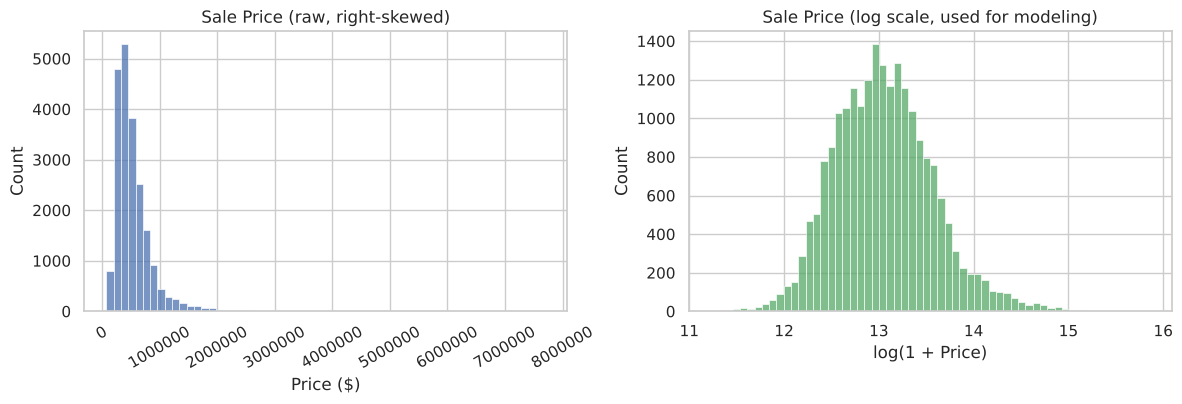

In [7]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4.2))
sns.histplot(df['price'], bins=60, ax=ax[0], color='#4C72B0')
ax[0].set_title('Sale Price (raw, right-skewed)'); ax[0].set_xlabel('Price ($)')
ax[0].ticklabel_format(style='plain', axis='x'); ax[0].tick_params(axis='x', rotation=30)
sns.histplot(np.log1p(df['price']), bins=60, ax=ax[1], color='#55A868')
ax[1].set_title('Sale Price (log scale, used for modeling)'); ax[1].set_xlabel('log(1 + Price)')
plt.tight_layout(); plt.show()

### 5.2 What moves with price?
Living area, construction grade, and bathrooms have the strongest positive relationships with price.
Distance to Seattle is the strongest negative one: the farther out, the cheaper, on average.

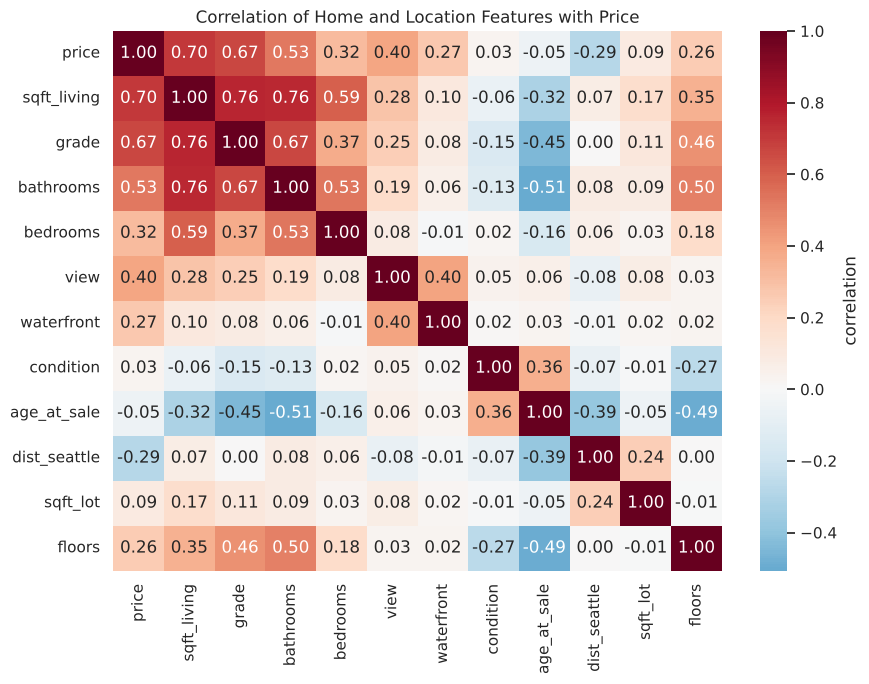

In [8]:
num_cols = ['price','sqft_living','grade','bathrooms','bedrooms','view','waterfront',
            'condition','age_at_sale','dist_seattle','sqft_lot','floors']
fig, ax = plt.subplots(figsize=(9, 7))
sns.heatmap(df[num_cols].corr(), annot=True, fmt='.2f', cmap='RdBu_r', center=0,
            ax=ax, cbar_kws={'label': 'correlation'})
ax.set_title('Correlation of Home and Location Features with Price')
plt.tight_layout(); plt.show()

### 5.3 The house side: size and quality
Price climbs with living area, and for any given size, higher-grade construction (lighter points) sits above
lower-grade homes. Size and quality reinforce each other.

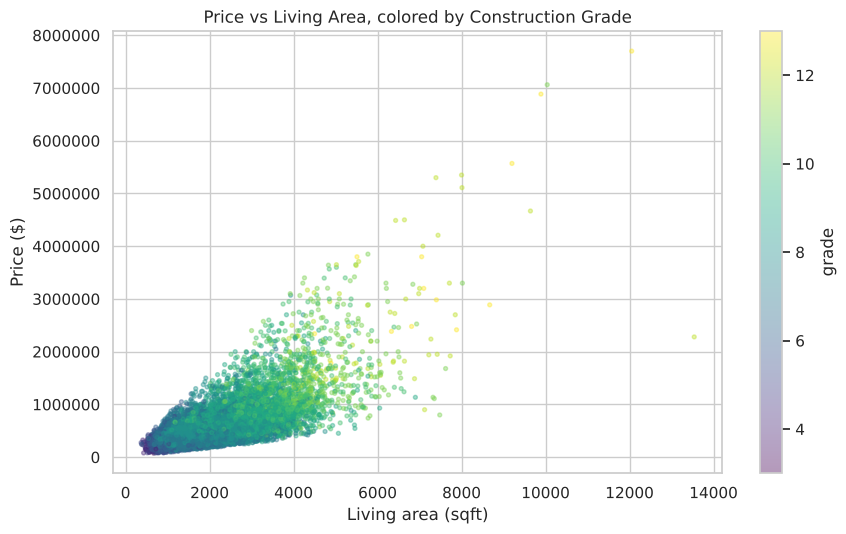

In [9]:
fig, ax = plt.subplots(figsize=(9, 5.5))
sc = ax.scatter(df['sqft_living'], df['price'], c=df['grade'], cmap='viridis', s=8, alpha=0.4)
ax.set_xlabel('Living area (sqft)'); ax.set_ylabel('Price ($)')
ax.set_title('Price vs Living Area, colored by Construction Grade')
ax.ticklabel_format(style='plain', axis='y'); plt.colorbar(sc, label='grade')
plt.tight_layout(); plt.show()

### 5.4 The location side: distance and ZIP code
Price falls steadily with distance from downtown, and the gap between neighborhoods is large: median prices
differ roughly **8x** between the cheapest and most expensive ZIP codes. Location is a primary driver, not a
tie-breaker.

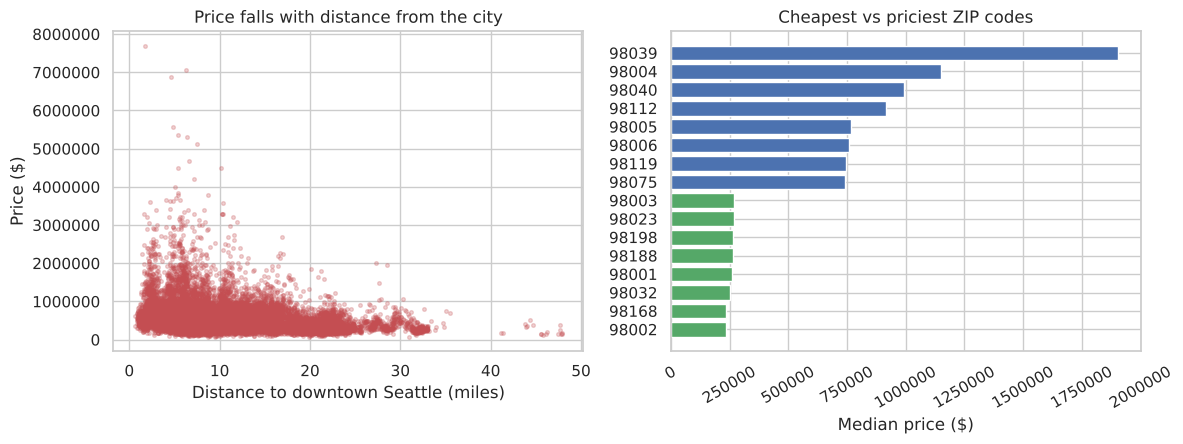

ZIP median price spread: $235,000 to $1,905,000  (8.1x)


In [10]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4.6))
ax[0].scatter(df['dist_seattle'], df['price'], s=7, alpha=0.25, color='#C44E52')
ax[0].set_xlabel('Distance to downtown Seattle (miles)'); ax[0].set_ylabel('Price ($)')
ax[0].set_title('Price falls with distance from the city')
ax[0].ticklabel_format(style='plain', axis='y')

zip_med = df.groupby('zipcode')['price'].median().sort_values()
extremes = pd.concat([zip_med.head(8), zip_med.tail(8)])
bar_colors = ['#55A868']*8 + ['#4C72B0']*8
ax[1].barh([str(z) for z in extremes.index], extremes.values, color=bar_colors)
ax[1].set_xlabel('Median price ($)'); ax[1].set_title('Cheapest vs priciest ZIP codes')
ax[1].ticklabel_format(style='plain', axis='x'); ax[1].tick_params(axis='x', rotation=30)
plt.tight_layout(); plt.show()
print(f'ZIP median price spread: ${zip_med.min():,.0f} to ${zip_med.max():,.0f}  ({zip_med.max()/zip_med.min():.1f}x)')

### 5.5 Where the value sits on the map
Plotting every sale by latitude and longitude, colored by price, shows value concentrated near Seattle and
the waterfront and thinning as you move outward.

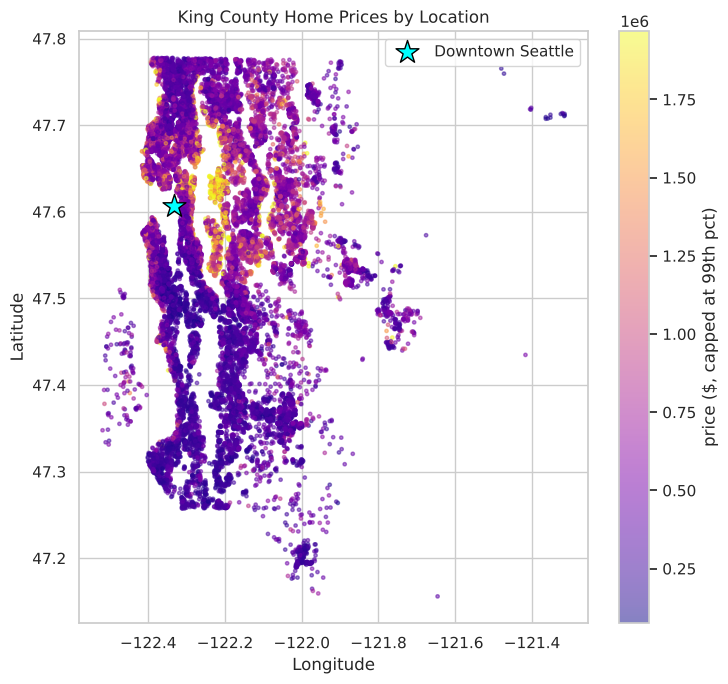

In [11]:
fig, ax = plt.subplots(figsize=(7.5, 7))
cap = df['price'].quantile(0.99)
sc = ax.scatter(df['long'], df['lat'], c=df['price'].clip(upper=cap), cmap='plasma', s=6, alpha=0.5)
ax.scatter(SEATTLE_LON, SEATTLE_LAT, marker='*', s=300, color='cyan',
           edgecolor='black', label='Downtown Seattle', zorder=5)
ax.set_xlabel('Longitude'); ax.set_ylabel('Latitude')
ax.set_title('King County Home Prices by Location'); ax.legend()
plt.colorbar(sc, label='price ($, capped at 99th pct)')
plt.tight_layout(); plt.show()

## 6. Modeling

**Target.** I predict `log(1 + price)` so the skew is controlled and errors read as roughly percentage errors,
then convert predictions back to dollars for reporting.

**Features.** Numeric home and distance features are standardized; `zipcode` is one-hot encoded so each
neighborhood carries its own level. A `ColumnTransformer` applies the right treatment to each, inside a
pipeline so the same steps run identically in cross-validation and on the test set.

**Models.** I fit five, from simple to flexible: Linear Regression (the baseline), Ridge and Lasso (linear with
regularization), and two tree ensembles, Random Forest and Gradient Boosting. The regularized and ensemble
models are tuned with cross-validation and grid search.

**Evaluation metric.** The headline metric is **RMSE in dollars**, because the audience thinks in dollars and
RMSE penalizes the large misses that matter most on a purchase this size. I report MAE (typical error) and R²
(share of variation explained) alongside it.

In [12]:
numeric_features = ['sqft_living','grade','bathrooms','bedrooms','sqft_lot','floors',
                    'waterfront','view','condition','age_at_sale','was_renovated',
                    'has_basement','sqft_living15','dist_seattle']
categorical_features = ['zipcode']

X = df[numeric_features + categorical_features].copy()
X['zipcode'] = X['zipcode'].astype(str)
y = np.log1p(df['price'])

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_STATE)

# Linear models: scale numerics, one-hot the ZIP code
pre_linear = ColumnTransformer([
    ('num', StandardScaler(), numeric_features),
    ('cat', OneHotEncoder(handle_unknown='ignore'), categorical_features)])

# Tree models: no scaling needed, still one-hot the ZIP code
pre_tree = ColumnTransformer([
    ('num', 'passthrough', numeric_features),
    ('cat', OneHotEncoder(handle_unknown='ignore'), categorical_features)])

print(f'Train: {X_train.shape[0]:,} rows   Test: {X_test.shape[0]:,} rows')

Train: 17,137 rows   Test: 4,285 rows


In [13]:
def evaluate(name, model):
    """Score a fitted model on the held-out test set, in dollars."""
    pred_log = model.predict(X_test)
    pred, true = np.expm1(pred_log), np.expm1(y_test)
    rmse = np.sqrt(mean_squared_error(true, pred))
    mae  = mean_absolute_error(true, pred)
    r2   = r2_score(y_test, pred_log)
    print(f'{name:24s} RMSE=${rmse:,.0f}   MAE=${mae:,.0f}   R2={r2:.3f}')
    return {'Model': name, 'RMSE': round(rmse), 'MAE': round(mae), 'R2': round(r2, 3)}

# Naive reference: predict the training-mean price for every home
naive = np.full(len(y_test), y_train.mean())
naive_rmse = np.sqrt(mean_squared_error(np.expm1(y_test), np.expm1(naive)))
print(f'{"Naive (mean)":24s} RMSE=${naive_rmse:,.0f}')

Naive (mean)             RMSE=$391,243


In [14]:
results = []

# 1. Linear regression, the baseline
linear = Pipeline([('pre', pre_linear), ('model', LinearRegression())]).fit(X_train, y_train)
results.append(evaluate('Linear (baseline)', linear))

# 2. Ridge, cross-validated penalty
ridge = GridSearchCV(Pipeline([('pre', pre_linear), ('model', Ridge())]),
                     {'model__alpha': [0.1, 1, 10]},
                     cv=5, scoring='neg_root_mean_squared_error').fit(X_train, y_train)
results.append(evaluate('Ridge (CV)', ridge))

# 3. Lasso, cross-validated penalty (also trims weak features)
lasso = GridSearchCV(Pipeline([('pre', pre_linear), ('model', Lasso(max_iter=20000))]),
                     {'model__alpha': [0.0005, 0.001]},
                     cv=5, scoring='neg_root_mean_squared_error').fit(X_train, y_train)
results.append(evaluate('Lasso (CV)', lasso))

Linear (baseline)        RMSE=$166,311   MAE=$78,847   R2=0.876


Ridge (CV)               RMSE=$166,286   MAE=$78,840   R2=0.876


Lasso (CV)               RMSE=$160,646   MAE=$80,651   R2=0.870


In [15]:
# 4. Random Forest, cross-validated
rf = GridSearchCV(Pipeline([('pre', pre_tree),
                            ('model', RandomForestRegressor(random_state=RANDOM_STATE, n_jobs=-1))]),
                  {'model__n_estimators': [200], 'model__min_samples_leaf': [1, 3]},
                  cv=3, scoring='neg_root_mean_squared_error').fit(X_train, y_train)
results.append(evaluate('Random Forest (CV)', rf))

# 5. Gradient Boosting, cross-validated
gb = GridSearchCV(Pipeline([('pre', pre_tree),
                            ('model', GradientBoostingRegressor(random_state=RANDOM_STATE))]),
                  {'model__n_estimators': [300], 'model__learning_rate': [0.05, 0.1], 'model__max_depth': [3]},
                  cv=3, scoring='neg_root_mean_squared_error').fit(X_train, y_train)
results.append(evaluate('Gradient Boosting (CV)', gb))

print('\nBest tuning choices:')
print('  Ridge alpha:', ridge.best_params_['model__alpha'])
print('  Lasso alpha:', lasso.best_params_['model__alpha'])
print('  Random Forest:', rf.best_params_)
print('  Gradient Boosting:', gb.best_params_)

Random Forest (CV)       RMSE=$143,749   MAE=$77,187   R2=0.872


Gradient Boosting (CV)   RMSE=$128,806   MAE=$75,282   R2=0.879

Best tuning choices:
  Ridge alpha: 0.1
  Lasso alpha: 0.0005
  Random Forest: {'model__min_samples_leaf': 1, 'model__n_estimators': 200}
  Gradient Boosting: {'model__learning_rate': 0.1, 'model__max_depth': 3, 'model__n_estimators': 300}


### 6.1 Model comparison

All five beat the naive guess by a wide margin. The two tree ensembles clearly outperform the linear models, and **Gradient Boosting is the best**, with the lowest dollar error.

,RMSE,MAE,R2
Model,,,
Linear (baseline),166311,78847,0.88
Ridge (CV),166286,78840,0.88
Lasso (CV),160646,80651,0.87
Random Forest (CV),143749,77187,0.87
Gradient Boosting (CV),128806,75282,0.88


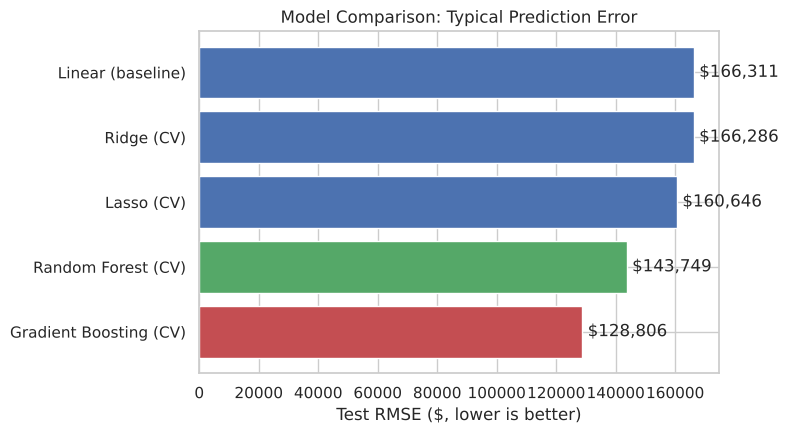

In [16]:
results_df = pd.DataFrame(results).set_index('Model')
display(results_df)

fig, ax = plt.subplots(figsize=(8, 4.5))
colors = ['#4C72B0','#4C72B0','#4C72B0','#55A868','#C44E52']
ax.barh(results_df.index[::-1], results_df['RMSE'][::-1], color=colors[::-1])
ax.set_xlabel('Test RMSE ($, lower is better)')
ax.set_title('Model Comparison: Typical Prediction Error')
for i, v in enumerate(results_df['RMSE'][::-1]):
    ax.text(v, i, f' ${v:,.0f}', va='center')
plt.tight_layout(); plt.show()

### 6.2 What the best model relies on

Gradient Boosting reports how much each feature contributed. Grouping the 70 ZIP-code columns back into a
single "location (ZIP code)" bar makes the picture readable. Construction grade and living area lead, and the
two location signals together (distance to the city plus ZIP code) are the next largest block.

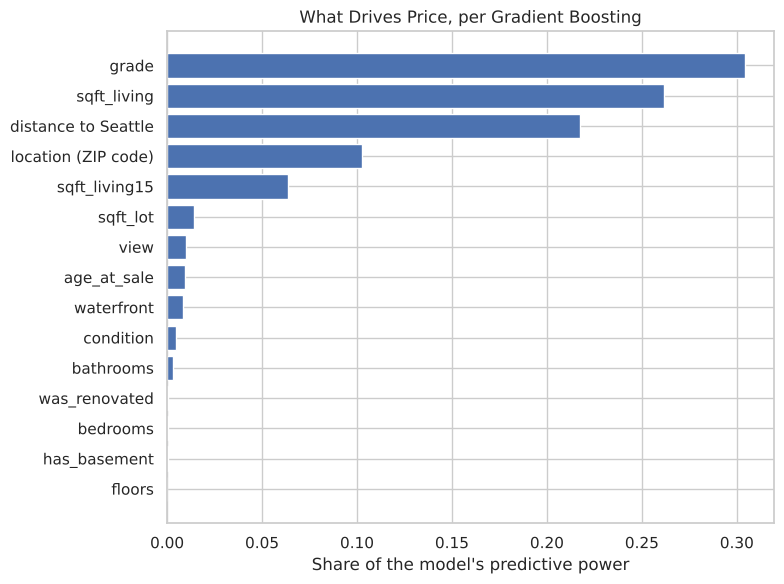

House features together: 68%   Location features together: 32%


In [17]:
# Pull feature importances out of the tuned Gradient Boosting model
ohe = gb.best_estimator_.named_steps['pre'].named_transformers_['cat']
feat_names = numeric_features + list(ohe.get_feature_names_out(['zipcode']))
importance = pd.Series(gb.best_estimator_.named_steps['model'].feature_importances_, index=feat_names)

# Collapse the ZIP dummies into one bar and tidy the distance label
grouped = importance[numeric_features].copy()
grouped['location (ZIP code)'] = importance[[f for f in feat_names if f.startswith('zipcode_')]].sum()
grouped = grouped.rename({'dist_seattle': 'distance to Seattle'}).sort_values(ascending=False)

fig, ax = plt.subplots(figsize=(8, 6))
ax.barh(grouped.index[::-1], grouped.values[::-1], color='#4C72B0')
ax.set_xlabel('Share of the model\'s predictive power')
ax.set_title('What Drives Price, per Gradient Boosting')
plt.tight_layout(); plt.show()

house_share = grouped.drop(['location (ZIP code)', 'distance to Seattle']).sum()
loc_share = grouped[['location (ZIP code)', 'distance to Seattle']].sum()
print(f'House features together: {house_share:.0%}   Location features together: {loc_share:.0%}')

### 6.3 A renovation what-if

Feature importance says what the model leans on, but a seller wants dollars. Using the Gradient Boosting model,
I take every home in the test set, nudge one feature up by a realistic amount, and measure how much the
predicted price moves. This turns the model into a simple "what if I improved this?" tool. These are
model-based associations, not guaranteed returns, but they rank the levers sensibly.

In [18]:
def whatif(feature, step, cap=None, label=None):
    base = np.expm1(gb.predict(X_test))
    bumped = X_test.copy()
    bumped[feature] = (bumped[feature] + step)
    if cap is not None:
        bumped[feature] = bumped[feature].clip(upper=cap)
    new = np.expm1(gb.predict(bumped))
    delta = (new - base)
    print(f'{label or feature:32s} median change: ${np.median(delta):>9,.0f}   '
          f'({np.median(delta/base):.1%})')

print('Predicted price change from a one-step improvement (median home):\n')
whatif('condition', 1, cap=5, label='Condition +1 (e.g. refresh/repair)')
whatif('grade', 1, cap=13, label='Grade +1 (higher-quality finish)')
whatif('was_renovated', 1, cap=1, label='Mark as renovated')
whatif('sqft_living', 250, label='Add 250 sqft of living space')
whatif('has_basement', 1, cap=1, label='Add a basement')

Predicted price change from a one-step improvement (median home):

Condition +1 (e.g. refresh/repair) median change: $   13,226   (2.8%)
Grade +1 (higher-quality finish) median change: $   60,495   (12.9%)
Mark as renovated                median change: $   16,685   (4.1%)
Add 250 sqft of living space     median change: $   19,956   (4.9%)


Add a basement                   median change: $   -1,511   (-0.6%)


## 7. Findings (plain language)

- **A buyer or seller can get a solid price estimate from a handful of facts.** The best model, Gradient
  Boosting, predicts sale price with a typical error of about **\$129,000** and explains roughly **88%** of the
  variation in price. That is far better than guessing the average, which is off by about \$391,000, and it
  improved as the models got more flexible (linear \~\$166K to boosting \~\$129K).

- **Price is set by two things: the house and the neighborhood.** Grouping the model's reliance, the **house
  itself (grade, living area, and the rest) accounts for most of the predictive power, with location (distance
  to the city plus ZIP code) the next largest block.** Neither side can be ignored.

- **On the house, quality and size dominate.** Construction grade and living area are the two biggest levers by
  a wide margin. View, waterfront, and condition matter in smaller amounts. **Bedroom count, floors, a
  basement, and a renovation flag add very little once grade and size are known.**

- **Location is something a seller inherits, not something they can change.** Distance to Seattle alone is one
  of the three strongest signals, and neighborhoods differ about 8x in median price. A home's ZIP code sets a
  large part of its price before any renovation.

## 8. Recommendations for a seller

- **Spend on quality and usable space, not on counts.** The renovation what-if shows the largest predicted
  gains come from improvements that raise the home's overall grade and finish, and from adding genuine living
  space. Money aimed at a higher bedroom count or a finished basement on its own barely moves the predicted
  price.

- **Let the neighborhood set your expectations.** If the home is in a high-demand ZIP code close to the city,
  much of its value is already there, and heavy renovation has less room to pay back. If it is farther out, the
  house has to compete more on its own quality, so targeted upgrades matter more.

- **Price with both levers in view.** A fair asking price reflects the house and its location together. The
  model gives a grounded estimate and, just as useful, flags which improvements would and would not change it.

## 9. Next steps

- Build a small lookup or calculator so a seller can enter a home's details and see an estimated price and the
  top few value levers.
- Add outside neighborhood data (schools, transit, crime) to deepen the location side beyond distance and ZIP.
- Test the approach on a more recent year and a different metro area to confirm it transfers.
- Explore partial-dependence plots to turn the what-if analysis into clearer dollar ranges for each upgrade.